# Cross-fault-size evaluation

How does a condition classifier transfer to fault sizes absent from training? At load 0, .007-inch faults provide training data, .014-inch faults provide validation, and .021-inch faults provide test data. The four classes are Healthy, IR, Ball, and OR.

Healthy windows come from disjoint portions of recording 97: indices 0–14, 16–30, and 32–46. Gaps avoid sample overlap, but all splits still share that healthy recording.

The default path reads protocol definitions and saved results without raw recordings or training. Follow the cells in order; optional execution controls appear after the result discussion. The original trained weights are unavailable. `CWRU_DATA_ROOT` supplies optional raw inputs and `CWRU_ARTIFACT_ROOT` selects output storage. Historical healthy recordings were acquired at 48 kHz, while the selected faults were acquired at 12 kHz; preprocessing treated both as 12 kHz without resampling.


In [1]:
from pathlib import Path
import os, sys, json
candidates = [Path.cwd(), *Path.cwd().parents]
REPO = next((p for p in candidates if (p / 'src/cwru_bearing').is_dir()), None)
if REPO is None:
    raise RuntimeError('Open this notebook from the repository checkout or its notebooks directory.')
sys.path.insert(0, str(REPO / 'src'))
from cwru_bearing.data import load_config, load_manifest
DATA_ROOT = Path(os.environ['CWRU_DATA_ROOT']) if os.environ.get('CWRU_DATA_ROOT') else None
ARTIFACT_ROOT = Path(os.environ.get('CWRU_ARTIFACT_ROOT', str(REPO / 'runs')))
print('Data configured:', DATA_ROOT is not None)
print('No training is enabled by default.')

In [2]:
import pandas as pd
from IPython.display import display, Image as DisplayImage
config = load_config('cross_fault_size')
manifest = load_manifest(config)
counts = manifest.groupby(['split', 'class_label']).size().unstack(fill_value=0)
counts.columns = [config['classes'][i] for i in counts.columns]
display(counts)


,Healthy,IR,Ball,OR
split,,,,
test,15,15,15,15
train,15,15,15,15
val,15,15,15,15


## Reading the historical result

The table and confusion matrices summarize saved training-notebook output, not a newly trained model. Rows of each matrix are true classes and columns are predictions. Macro-F1 averages class-specific F1 scores equally, so it complements the overall fraction of correctly classified windows.


,Accuracy (%),Macro-F1 (%)
0,70.0,68.38


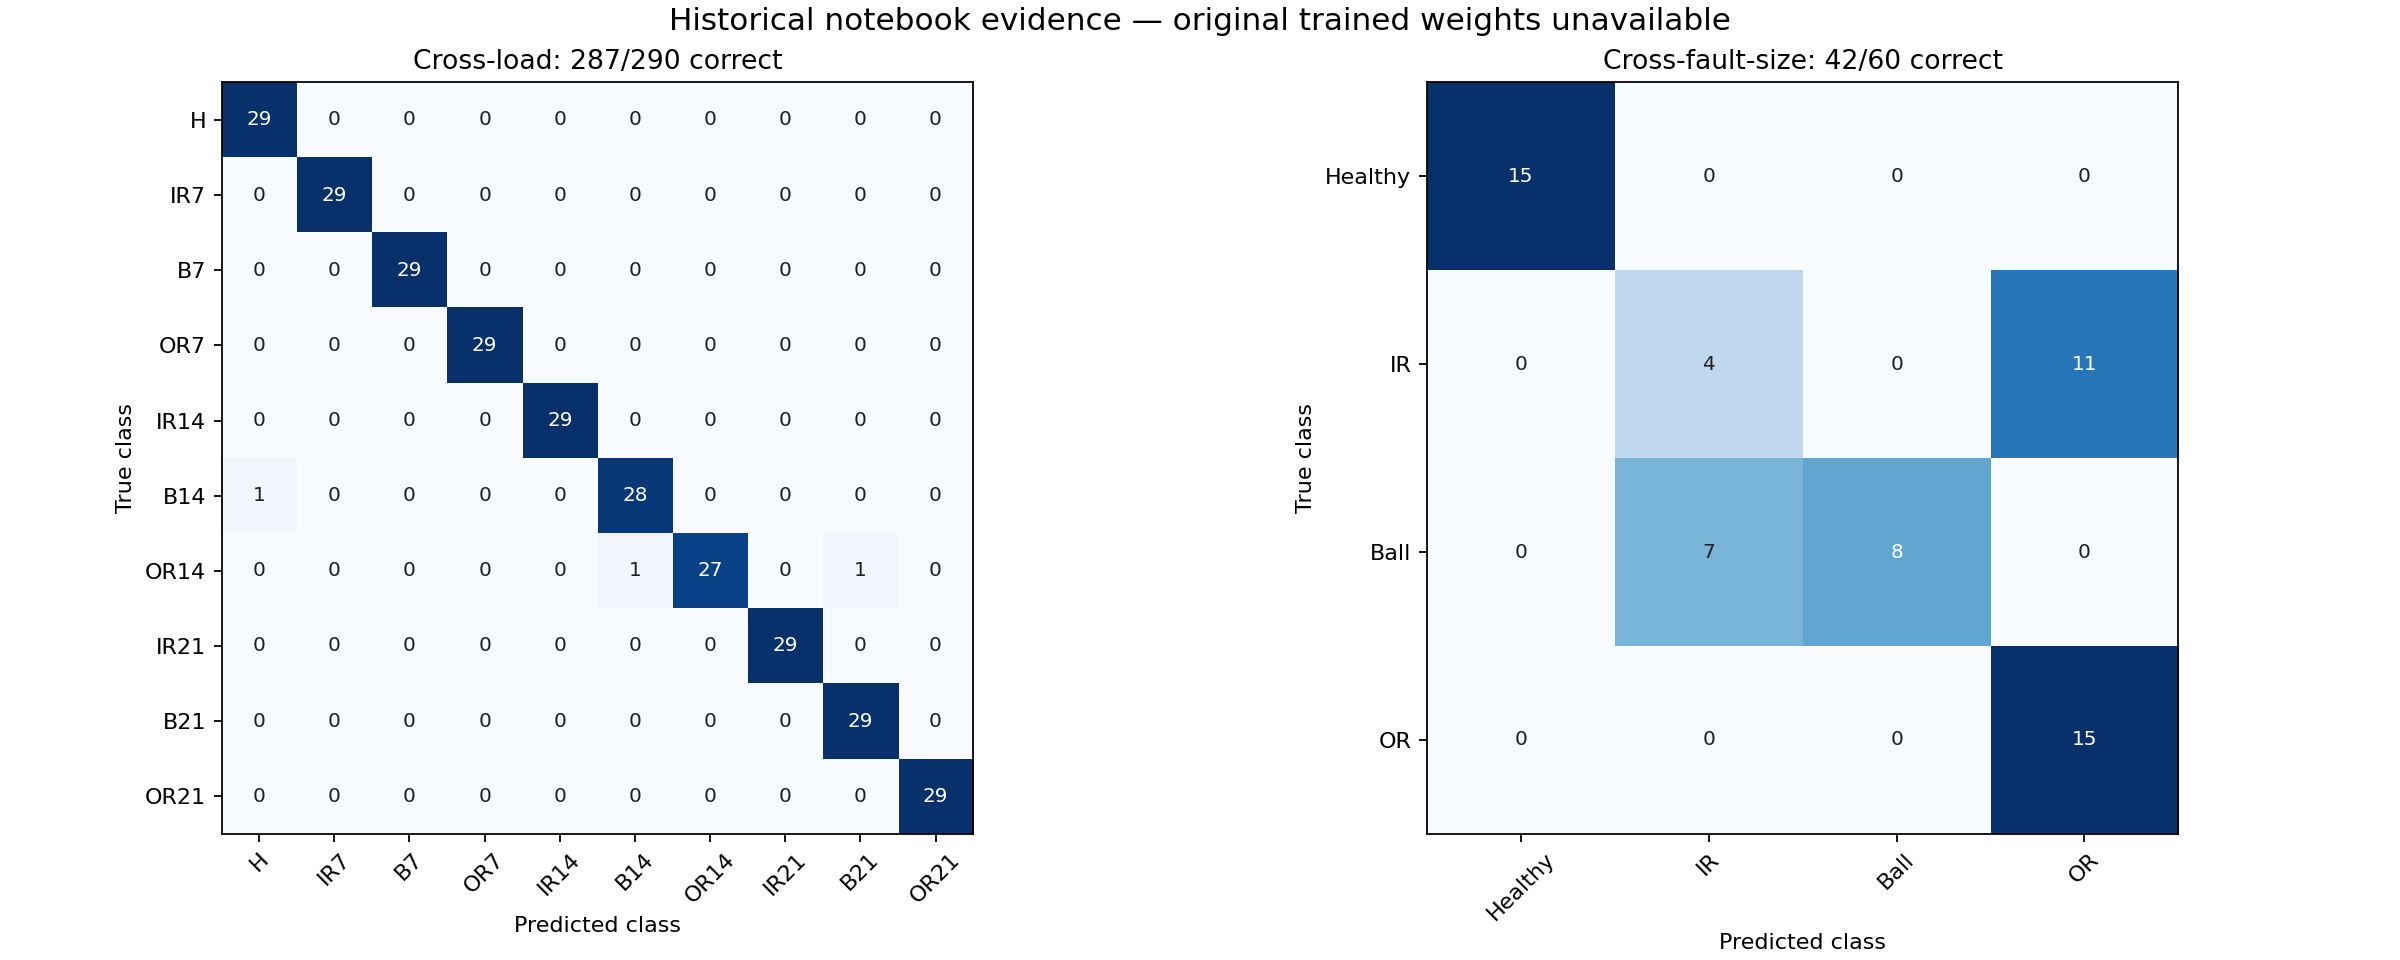

In [3]:
historical = json.loads((REPO / 'results/historical/results.json').read_text(encoding='utf-8'))
result = historical['cross_fault_size']
display(pd.DataFrame([{'Accuracy (%)': 100*result['accuracy'],
                       'Macro-F1 (%)': 100*result['macro_f1']}]).round(2))
display(DisplayImage(filename=str(REPO / 'figures/historical_confusion_matrices.png')))


Cross-fault-size classified 42 of 60 windows correctly. Eleven inner-race windows were predicted as outer-race faults, and seven ball-fault windows were predicted as inner-race faults. Healthy and outer-race windows were all correct. Accuracy among faulty windows alone was 27/45 (60%). This pattern identifies a transfer failure, but does not prove which signal cues the CNN used.

The cross-load experiment has different classes, sample counts, and splits. Its higher score does not isolate fault size as the cause of the difference.


## Optional execution

Set the named controls below only after reading [installation and execution](../docs/reproduction.md). Image generation needs raw recordings; training needs validated generated images and may download torchvision ImageNet weights. Evaluation needs a checkpoint from a new run. All three actions remain disabled by default.

Choose fresh output directories because overwriting is rejected. In Colab, use persistent artifact storage if outputs must survive a runtime reset. Enabling these branches creates new experiment outputs, not a reproduction claim for the saved scores.


In [4]:
RUN_PREPROCESS = False
RUN_TRAINING = False
RUN_EVALUATION = False
IMAGE_ROOT = ARTIFACT_ROOT / 'images' / 'cross_fault_size'
RUN_ROOT = ARTIFACT_ROOT / 'cross_fault_size' / 'run01'
CHECKPOINT = RUN_ROOT / 'stage2_best.pth'
EVALUATION_ROOT = ARTIFACT_ROOT / 'cross_fault_size' / 'evaluation01'

In [5]:
if RUN_PREPROCESS:
    if DATA_ROOT is None:
        raise RuntimeError('Configure CWRU_DATA_ROOT first.')
    from cwru_bearing.data import validate_recordings
    from cwru_bearing.preprocessing import generate
    validate_recordings(DATA_ROOT, config)
    print(generate(DATA_ROOT, IMAGE_ROOT, config))
else:
    print('Preprocessing disabled.')

In [6]:
if RUN_TRAINING:
    from cwru_bearing.training import run_training
    print(run_training(IMAGE_ROOT, RUN_ROOT, config))
else:
    print('Training disabled; no model has been trained.')

In [7]:
if RUN_EVALUATION:
    from cwru_bearing.training import evaluate_checkpoint
    print(evaluate_checkpoint(CHECKPOINT, IMAGE_ROOT, EVALUATION_ROOT))
else:
    print('Checkpoint evaluation disabled; original weights are unavailable.')

## Training details and interpretation limits

Stage two calls `model.train()` and places every BatchNorm layer in evaluation mode. Earlier frozen stochastic layers remain active. The original section did not reset its seed, so the runner preserves that policy and captures available ambient RNG state for new runs. This cannot reconstruct the missing historical Colab state.

New checkpoints, histories, configuration, provenance, and predictions go under `RUN_ROOT`. Consult [experimental protocols](../docs/protocols.md) for exact settings and [scientific limitations](../docs/scientific_audit.md) for the limits of the scientific claims.


[Project overview](../README.md) | [Previous notebook](04_cross_load.ipynb)
